## Salary Prediciton

In [2]:
!pip install scikit-learn

  Using cached joblib-1.5.1-py3-none-any.whl.metadata (5.6 kB)
Using cached joblib-1.5.1-py3-none-any.whl (307 kB)
  Attempting uninstall: joblib
    Found existing installation: joblib 1.1.1
    Uninstalling joblib-1.1.1:
      Successfully uninstalled joblib-1.1.1


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pandas-profiling 3.2.0 requires joblib~=1.1.0, but you have joblib 1.5.1 which is incompatible.
pandas-profiling 3.2.0 requires visions[type_image_path]==0.7.4, but you have visions 0.8.1 which is incompatible.


In [3]:
## Salary Predictions
#  What is the Goal?
# We want to predict someone's salary based on their years of work experienc


In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



In [5]:
salary_df = pd.read_csv("../dataset/Salary_Data.csv")
salary_df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [6]:
salary_df.describe().T

,count,mean,std,min,25%,50%,75%,max
YearsExperience,30.0,5.313333,2.837888,1.1,3.20,4.7,7.70,10.5
Salary,30.0,76003.000000,27414.429785,37731.0,56720.75,65237.0,100544.75,122391.0


In [7]:
salary_df['Salary'].value_counts()

Salary
39343.0     1
46205.0     1
122391.0    1
112635.0    1
116969.0    1
105582.0    1
109431.0    1
113812.0    1
101302.0    1
98273.0     1
91738.0     1
93940.0     1
81363.0     1
83088.0     1
66029.0     1
67938.0     1
61111.0     1
57081.0     1
56957.0     1
55794.0     1
63218.0     1
57189.0     1
64445.0     1
54445.0     1
60150.0     1
56642.0     1
39891.0     1
43525.0     1
37731.0     1
121872.0    1
Name: count, dtype: int64

In [8]:
salary_df.shape

(30, 2)

In [9]:
salary_df.isna().sum()

YearsExperience    0
Salary             0
dtype: int64

## Data visualization

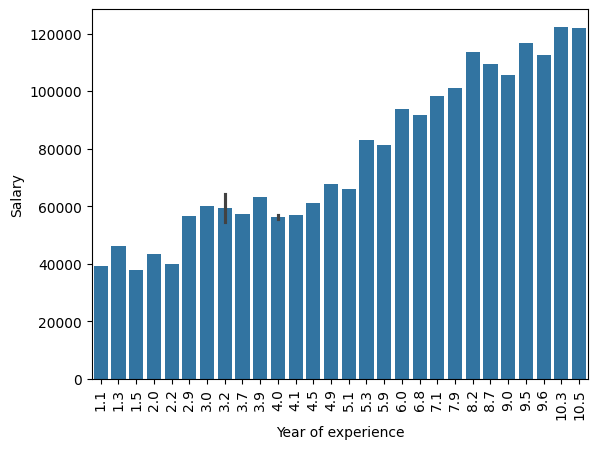

In [10]:
sns.barplot(x='YearsExperience',y='Salary',data=salary_df)
plt.xlabel("Year of experience")
plt.xticks(rotation = 90)
plt.ylabel("Salary")
plt.show()

<Figure size 800x600 with 0 Axes>

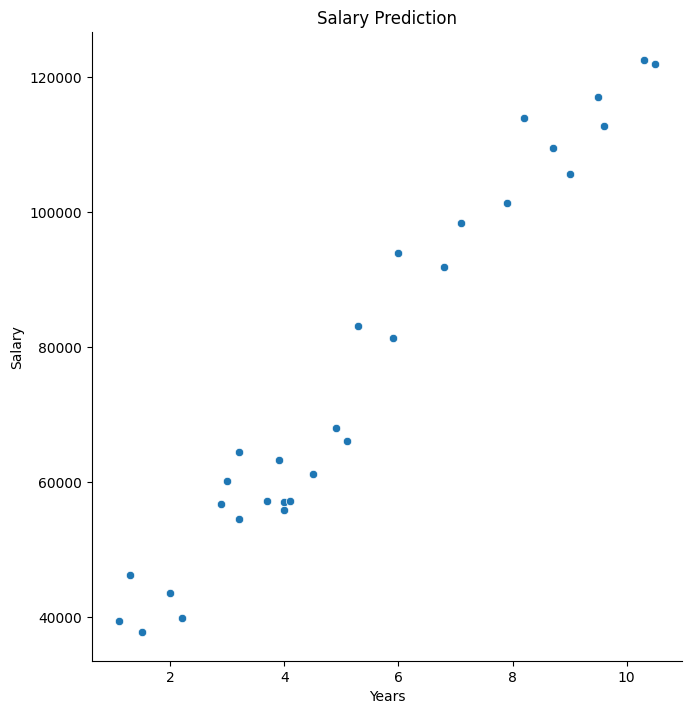

In [11]:
plt.figure(figsize=(8,6))
sns.pairplot(salary_df, x_vars=['YearsExperience'], y_vars=['Salary'], height=7, kind='scatter')

plt.xlabel('Years')
plt.ylabel('Salary')
plt.title('Salary Prediction')
plt.show()

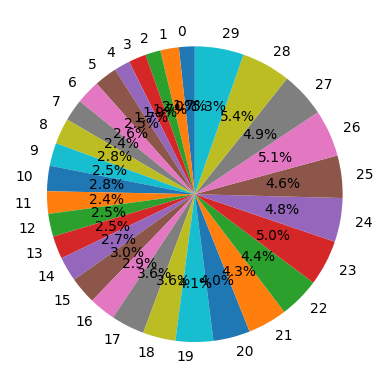

In [12]:
plt.pie(salary_df['Salary'],labels=salary_df.index,autopct='%1.1f%%',startangle=90)
plt.show()


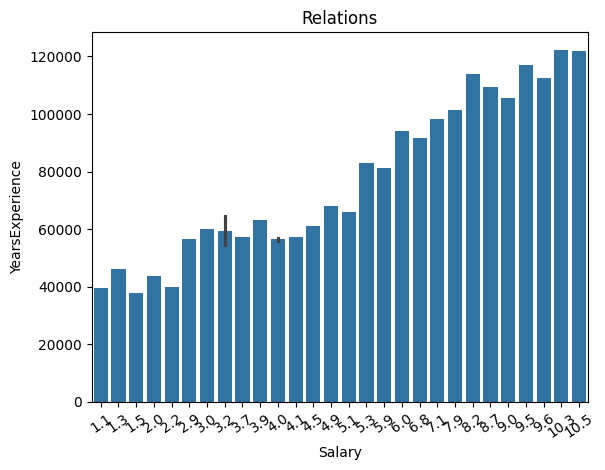

In [13]:
sns.barplot(x='YearsExperience',y='Salary',data=salary_df)
plt.xlabel("Salary")
plt.xticks(rotation = 35)
plt.ylabel("YearsExperience")
plt.title("Relations")
plt.show()

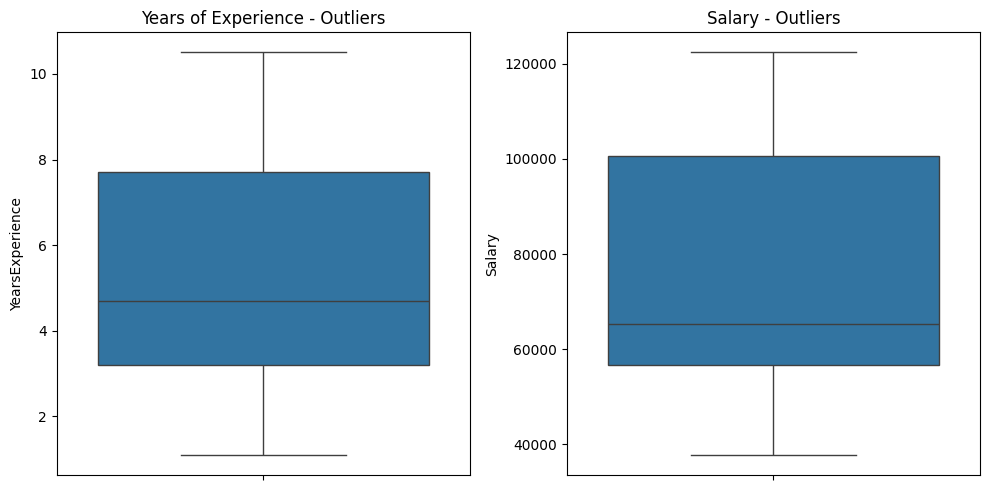

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

# Boxplot for both features
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=salary_df['YearsExperience'])
plt.title("Years of Experience - Outliers")

plt.subplot(1, 2, 2)
sns.boxplot(y=salary_df['Salary'])
plt.title("Salary - Outliers")

plt.tight_layout()
plt.show()


In [15]:
def detect_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[column] < lower_bound) | (df[column] > upper_bound)]

# Find outliers
outliers_experience = detect_outliers_iqr(salary_df, 'YearsExperience')
outliers_salary = detect_outliers_iqr(salary_df, 'Salary')

print("Outliers in YearsExperience:\n", outliers_experience)
print("Outliers in Salary:\n", outliers_salary)


Outliers in YearsExperience:
 Empty DataFrame
Columns: [YearsExperience, Salary]
Index: []
Outliers in Salary:
 Empty DataFrame
Columns: [YearsExperience, Salary]
Index: []


In [16]:
def remove_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]

# Remove outliers
clean_df = remove_outliers(salary_df, 'YearsExperience')
clean_df = remove_outliers(clean_df, 'Salary')

print(f"Original data size: {salary_df.shape}")
print(f"After outlier removal: {clean_df.shape}")


Original data size: (30, 2)
After outlier removal: (30, 2)


## Split dataset

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

We know normal linera formula:
    y = mx + c
    so we need to select x and y where x = features(input) 
                        and y = target varibale (y)

In [18]:
X = clean_df["YearsExperience"].values
y = clean_df["Salary"].values





In [19]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# creating an object of class linear regression
lr = LinearRegression()
lr.fit(X_train.reshape(-1, 1), y_train.reshape(-1, 1))  # -1 = automatically rows 1=automatically read =column

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [20]:
X_train

array([10.3,  8.7,  4. ,  1.1,  2.2,  5.1,  2.9,  4.1,  4. ,  7.9,  1.3,
        1.5,  9. ,  2. ,  7.1,  9.5,  5.9, 10.5,  6.8,  3.2,  3.9,  4.5,
        6. ,  3. ])

In [21]:
y_pred = lr.predict(X_test.reshape(-1, 1))

In [22]:
y_pred

array([[115790.21011287],
       [ 71498.27809463],
       [102596.86866063],
       [ 75267.80422384],
       [ 55477.79204548],
       [ 60189.69970699]])

In [23]:


from sklearn.metrics import mean_squared_error, r2_score

print("MSE:", mean_squared_error(y_test, y_pred))
print("R² Score:", r2_score(y_test, y_pred))

MSE: 49830096.85590839
R² Score: 0.9024461774180497


In [1]:
!pip install joblib

In [24]:
import joblib

# Save the trained model
joblib.dump(lr,"salary_model_no_outliers.joblib")


['salary_model_no_outliers.joblib']

In [25]:
# Load the trained model
model_path = "salary_model_no_outliers.joblib"
model = joblib.load(model_path)

In [30]:
# Define prediction function
def predict_salary(years_of_experience):
    """
    Predict salary based on years of experience.

    Parameters:
    years_of_experience (float or int): Number of years of work experience.

    Returns:
    float: Predicted salary.
    """
    # Convert input to 2D array (required by sklearn)
    input_array = np.array([[years_of_experience]])
    
    # Make prediction
    predicted_salary = model.predict(input_array)
    
    return predicted_salary[0]

# Example usage:
print("Predicted salary for 15 years of experience:", predict_salary(15))
print("Predicted salary for 10 years of experience:", predict_salary(10))

Predicted salary for 15 years of experience: [166678.81285724]
Predicted salary for 10 years of experience: [119559.73624209]
